In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import END, START
from langgraph.graph.state import StateGraph
from langgraph.graph.message import add_messages #reducer
from langgraph.prebuilt import ToolNode
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage
import os
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["LANGSMITH_API_KEY"] = os.getenv("LANGSMITH_API_KEY")
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGSMITH_PROJECT"] = os.getenv("LANGSMITH_PROJECT", "Tutorial1") # this is the project name in LangSmith website
os.environ["LANGCHAIN_PROJECT"] = os.getenv("LANGCHAIN_PROJECT", "Tutorial1")


In [3]:
from langchain.chat_models import init_chat_model
llm = init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(output_version=None, profile={'max_input_tokens': 131072, 'max_output_tokens': 32768, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True}, client=<groq.resources.chat.completions.Completions object at 0x000001C9E0D32DE0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001C9E106AF00>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None)

In [4]:
class State(TypedDict): # we used TypeDict as we need a key value pair response
    messages: Annotated[list[BaseMessage],add_messages] #add_messages is the reducer

In [5]:
## Graph With Tool Call

@tool
def add(a:float,b:float):
    """ Add two numbers """
    return a+b

tools = [add]
tool_node = ToolNode([add]) # added a tool node in the graph

llm_with_tool = llm.bind_tools([add])

def call_llm_model(state:State):
    return {"messages": [llm_with_tool.invoke(state['messages'])]}

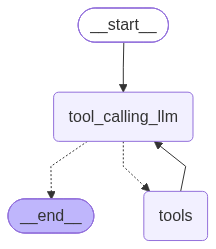

In [6]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# Node definition
def call_llm_model(state:State):
    return {"messages": [llm_with_tool.invoke(state['messages'])]}

# Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",call_llm_model)
builder.add_node("tools", ToolNode(tools))

# Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)
builder.add_edge("tools", "tool_calling_llm")

# Compile the Graph 
graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
response = graph.invoke({"messages":"What is the recent AI news"})

In [8]:
response

{'messages': [HumanMessage(content='What is the recent AI news', additional_kwargs={}, response_metadata={}, id='97fe2ea8-0f72-4f44-a2f9-e3909cefc551'),
  AIMessage(content='**Recent AI News (as of\u202fNov\u202f2026)**  \n\nBelow is a quick roundup of the most notable AI developments from the past few months, grouped by theme. (All dates are in 2026 unless noted otherwise.)\n\n---\n\n## 1.\u202fBreakthrough Models & Technologies  \n\n| Date | Headline | Why It Matters |\n|------|----------|----------------|\n| **Oct\u202f28** | **Google DeepMind releases *Gemini‑2* (1‑trillion‑parameter multimodal model)** | Gemini‑2 outperforms GPT‑4‑Turbo on most benchmark suites (MMLU, BIG‑Bench, VQA) while using 30\u202f% less inference compute. It introduces “dynamic‑token routing,” allowing the model to allocate more compute to difficult sub‑tasks on‑the‑fly. |\n| **Oct\u202f12** | **OpenAI launches *ChatGPT‑5* with “self‑refine” loop** | The model can internally generate a draft answer, critiqu

In [9]:
response = graph.invoke({"messages": "What is 2 plus 2 using tool attached?"})
response

{'messages': [HumanMessage(content='What is 2 plus 2 using tool attached?', additional_kwargs={}, response_metadata={}, id='c4b78ad5-9ee5-498b-84d4-50e62ed711b2'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks "What is 2 plus 2 using tool attached?" There\'s a tool "functions.add" that adds two numbers. We should call it with a=2, b=2. Then respond with the result.', 'tool_calls': [{'id': 'fc_9f514670-7f73-424a-a97e-b88d5c0ce103', 'function': {'arguments': '{"a":2,"b":2}', 'name': 'add'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 79, 'prompt_tokens': 131, 'total_tokens': 210, 'completion_time': 0.16587282, 'completion_tokens_details': {'reasoning_tokens': 46}, 'prompt_time': 0.008799359, 'prompt_tokens_details': None, 'queue_time': 0.366926288, 'total_time': 0.174672179}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_b1dd3e7a63', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': Non